# SAST-LLM Benchmark — Hasil Evaluasi LLM

Perbandingan tiga LLM lokal pada **OWASP BenchmarkJava v1.2** untuk tiga pertanyaan:

1. **Deteksi kerentanan** — apakah model bisa membedakan kode yang vulnerable dan yang aman?
2. **Klasifikasi CWE** — jika kode vulnerable, apakah model menyebut CWE yang tepat?
3. **Biaya waktu** — berapa lama model menganalisis seluruh dataset?

**Alur notebook:** Setup → Dataset & cakupan → Deteksi → CWE → Waktu → Kesimpulan → Ekspor.
Seluruh grafik dan tabel otomatis disimpan ke `results/comparison/` sehingga bisa langsung dipakai di slide.

## 0. Setup

Sel di bawah memakai `%pip` agar paket terpasang **di kernel yang sedang dipakai notebook ini**.
(Error `No module named 'pandas'` sebelumnya terjadi karena paket terpasang di interpreter yang berbeda dari kernel.)
Jalankan sekali, lalu **restart kernel** jika ini pertama kali paket terpasang.

In [53]:
%pip install -q pandas matplotlib jinja2

Note: you may need to restart the kernel to use updated packages.


In [54]:
from pathlib import Path
import csv
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# ------------------------------------------------------------------
# Konfigurasi
# ------------------------------------------------------------------
ROOT = Path.cwd()
GROUND_TRUTH = ROOT / "benchmark/BenchmarkJava/expectedresults-1.2.csv"
LLMS = {
    "Qwen2.5-3B": ROOT / "results/llm/raw/qwen2.5-3b.jsonl",
    "Gemma4-E4B": ROOT / "results/llm/raw/gemma4-e4b.jsonl",
    "Qwen3-8B": ROOT / "results/llm/raw/qwen3-8b.jsonl",
}
MODELS = list(LLMS)

FIG_DIR = ROOT / "results/comparison/figures"
TABLE_DIR = ROOT / "results/comparison/tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Satu warna tetap per model, dipakai konsisten di semua grafik
PALETTE = ["#4C78A8", "#F58518", "#54A24B", "#B279A2", "#E45756"]
COLORS = {m: PALETTE[i % len(PALETTE)] for i, m in enumerate(MODELS)}

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


def save_table(df, name):
    df.to_csv(TABLE_DIR / f"{name}.csv")


print("Repository:", ROOT)

Repository: /home/nasyikhqusyairy/Projects/repositories/sast-llm-benchmark


## 1. Dataset dan cakupan prediksi

Sebelum membandingkan model, kita pastikan dulu **berapa banyak output model yang valid**.
Output yang gagal di-parse tidak ikut dihitung di metrik, jadi cakupan yang rendah bisa membuat perbandingan bias.

In [55]:
def normalize_cwe(value):
    if value is None:
        return None
    value = str(value).strip()
    if not value or value.lower() in {"none", "null", "nan"}:
        return None
    return value.upper() if value.upper().startswith("CWE-") else f"CWE-{value}"


def parse_ground_truth(path):
    out = {}
    with path.open(encoding="utf-8") as f:
        reader = csv.reader(line for line in f if not line.startswith("#"))
        for row in reader:
            if len(row) < 4:
                continue
            out[row[0].strip()] = {
                "category": row[1].strip(),
                "vulnerable": row[2].strip().lower() == "true",
                "cwe": normalize_cwe(row[3]),
            }
    return out


def parse_llm(path):
    """Kembalikan (prediksi valid, daftar waktu, jumlah record)."""
    preds, times, n_records = {}, [], 0
    with path.open(encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            try:
                r = json.loads(line)
            except json.JSONDecodeError:
                continue
            n_records += 1

            name = r.get("test_name")
            parsed = r.get("parsed")
            if name and isinstance(parsed, dict) and isinstance(parsed.get("vulnerable"), bool):
                preds[name] = parsed

            elapsed = r.get("elapsed_seconds")
            if r.get("success") and isinstance(elapsed, (int, float)):
                times.append(float(elapsed))
    return preds, times, n_records


gt = parse_ground_truth(GROUND_TRUTH)
data = {m: parse_llm(p) for m, p in LLMS.items()}
N = len(gt)

gt_df = pd.DataFrame.from_dict(gt, orient="index")
n_vuln = int(gt_df["vulnerable"].sum())
display(Markdown(
    f"**{N:,}** test case &nbsp;|&nbsp; **{n_vuln:,}** vulnerable ({n_vuln / N:.1%}) "
    f"&nbsp;|&nbsp; **{N - n_vuln:,}** aman ({(N - n_vuln) / N:.1%})"
))

cat_overview = gt_df.groupby("category")["vulnerable"].agg(Total="size", Vulnerable="sum")
cat_overview["Vulnerable"] = cat_overview["Vulnerable"].astype(int)
cat_overview["Safe"] = cat_overview["Total"] - cat_overview["Vulnerable"]
display(cat_overview)
save_table(cat_overview, "dataset_overview")

**2,740** test case &nbsp;|&nbsp; **1,415** vulnerable (51.6%) &nbsp;|&nbsp; **1,325** aman (48.4%)

,Total,Vulnerable,Safe
category,,,
cmdi,251,126,125
crypto,246,130,116
hash,236,129,107
ldapi,59,27,32
pathtraver,268,133,135
securecookie,67,36,31
sqli,504,272,232
trustbound,126,83,43
weakrand,493,218,275


In [56]:
coverage = pd.DataFrame({
    m: {
        "Records in JSONL": n_rec,
        "Valid predictions": len(preds),
        "Missing / invalid": N - len(preds),
        "Coverage (%)": 100 * len(preds) / N,
    }
    for m, (preds, _, n_rec) in data.items()
}).T
display(coverage.style.format({
    "Records in JSONL": "{:,.0f}", "Valid predictions": "{:,.0f}",
    "Missing / invalid": "{:,.0f}", "Coverage (%)": "{:.1f}",
}))
save_table(coverage, "coverage")

,Records in JSONL,Valid predictions,Missing / invalid,Coverage (%)
Qwen2.5-3B,"2,740","2,740",0,100.0
Gemma4-E4B,"2,740","2,740",0,100.0
Qwen3-8B,"2,740","2,740",0,100.0


## 2. Deteksi kerentanan (vulnerable vs aman)

*Positive class = vulnerable.* Cara membaca:
**Precision** = dari semua yang ditandai vulnerable, berapa yang benar;
**Recall** = dari semua yang memang vulnerable, berapa yang berhasil ditemukan;
**FPR** = seberapa sering kode aman salah dituduh vulnerable (semakin rendah semakin baik).

In [57]:
OUTCOMES = ["TP", "FP", "FN", "TN"]

rows = []
for m, (preds, _, _) in data.items():
    for name, t in gt.items():
        p = preds.get(name)
        if p is None:
            continue
        rows.append((m, name, t["category"], t["vulnerable"], p["vulnerable"],
                     t["cwe"], normalize_cwe(p.get("cwe"))))

df = pd.DataFrame(rows, columns=["model", "test", "category", "actual", "pred", "cwe_true", "cwe_pred"])
df["actual"] = df["actual"].astype(bool)
df["pred"] = df["pred"].astype(bool)
df["outcome"] = np.select(
    [df.actual & df.pred, ~df.actual & df.pred, df.actual & ~df.pred],
    ["TP", "FP", "FN"],
    default="TN",
)


def add_metrics(c):
    c = c.copy()
    tp, fp, fn, tn = (c[k] for k in OUTCOMES)

    def div(a, b):
        return (a / b.where(b > 0)).fillna(0.0)

    c["Precision"] = div(tp, tp + fp)
    c["Recall"] = div(tp, tp + fn)
    c["F1"] = div(2 * c["Precision"] * c["Recall"], c["Precision"] + c["Recall"])
    c["Accuracy"] = div(tp + tn, tp + fp + fn + tn)
    c["FPR"] = div(fp, fp + tn)
    return c


counts = (df.groupby(["model", "outcome"]).size()
            .unstack(fill_value=0)
            .reindex(index=MODELS, columns=OUTCOMES, fill_value=0))
det = add_metrics(counts)

fmt = {c: "{:,}" for c in OUTCOMES}
fmt.update({c: "{:.4f}" for c in ["Precision", "Recall", "F1", "Accuracy", "FPR"]})
display(
    det.style.format(fmt)
    .highlight_max(subset=["Precision", "Recall", "F1", "Accuracy"], color="#0011ac")
    .highlight_min(subset=["FPR"], color="#0011ac")
)
save_table(det, "detection_overall")

outcome,TP,FP,FN,TN,Precision,Recall,F1,Accuracy,FPR
model,,,,,,,,,
Qwen2.5-3B,"1,415","1,325",0,0,0.5164,1.0000,0.6811,0.5164,1.0000
Gemma4-E4B,"1,244",989,171,336,0.5571,0.8792,0.6820,0.5766,0.7464
Qwen3-8B,"1,404","1,290",11,35,0.5212,0.9922,0.6834,0.5252,0.9736


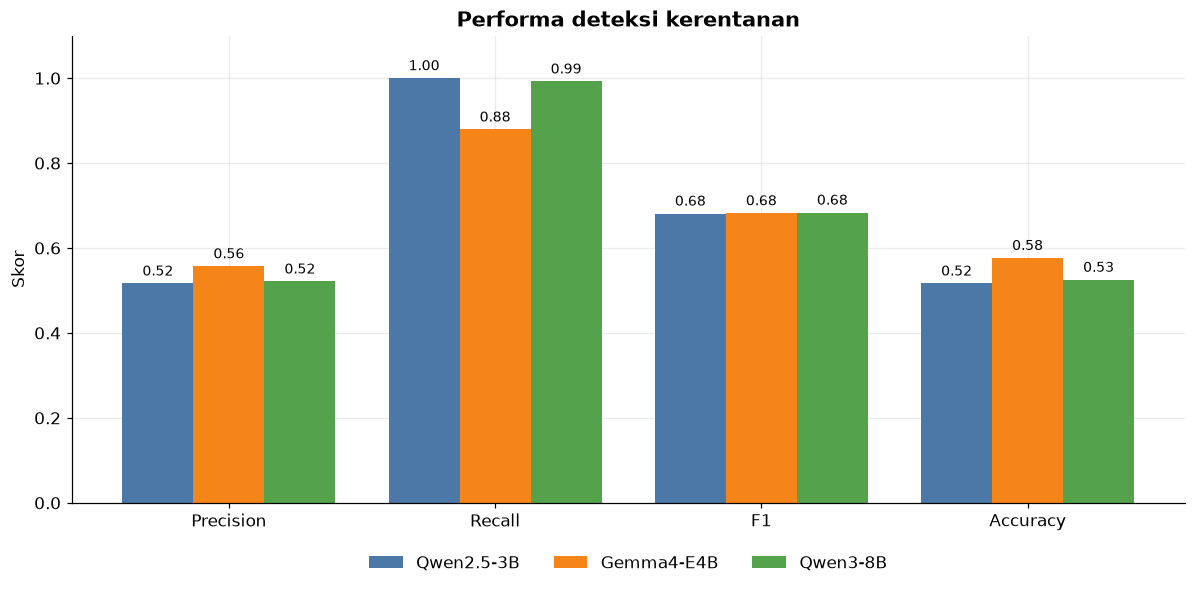

In [58]:
metric_names = ["Precision", "Recall", "F1", "Accuracy"]
x = np.arange(len(metric_names))
width = 0.8 / len(MODELS)

fig, ax = plt.subplots(figsize=(11, 5.5))
for i, m in enumerate(MODELS):
    bars = ax.bar(x + (i - (len(MODELS) - 1) / 2) * width, det.loc[m, metric_names].values,
                  width, label=m, color=COLORS[m])
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Skor")
ax.set_title("Performa deteksi kerentanan")
ax.legend(frameon=False, ncol=len(MODELS), loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
save_fig(fig, "detection_metrics")
plt.show()

### Confusion matrix

Warna = persentase **per baris** (dari semua kasus aktual), angka = jumlah kasus.
Sel kanan-atas (aman → ditandai vulnerable) adalah false positive; sel kiri-bawah (vulnerable → dianggap aman) adalah false negative.

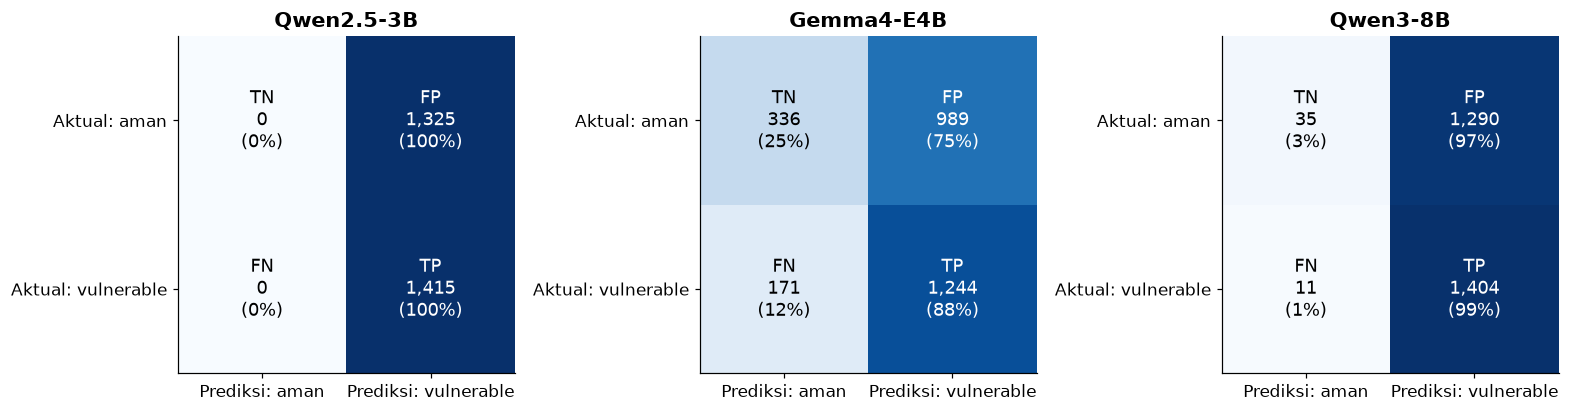

In [59]:
fig, axes = plt.subplots(
    1,
    len(MODELS),
    figsize=(4.8 * len(MODELS), 4.4),
    squeeze=False
)

labels = np.array([
    ["TN", "FP"],
    ["FN", "TP"]
])

for ax, m in zip(axes[0], MODELS):
    r = det.loc[m]

    mat = np.array([
        [r["TN"], r["FP"]],
        [r["FN"], r["TP"]]
    ], dtype=float)

    row_sum = mat.sum(axis=1, keepdims=True)

    norm = np.divide(
        mat,
        row_sum,
        out=np.zeros_like(mat),
        where=row_sum > 0
    )

    ax.imshow(
        norm,
        cmap="Blues",
        vmin=0,
        vmax=1
    )

    ax.grid(False)

    ax.set_xticks([0, 1])
    ax.set_xticklabels([
        "Prediksi: aman",
        "Prediksi: vulnerable"
    ])

    ax.set_yticks([0, 1])
    ax.set_yticklabels([
        "Aktual: aman",
        "Aktual: vulnerable"
    ])

    ax.set_title(m)

    for i in range(2):
        for j in range(2):
            label = labels[i, j]

            ax.text(
                j,
                i,
                f"{label}\n"
                f"{int(mat[i, j]):,}\n"
                f"({norm[i, j]:.0%})",
                ha="center",
                va="center",
                fontsize=12,
                color="white" if norm[i, j] > 0.55 else "black"
            )

plt.tight_layout()

save_fig(
    fig,
    "detection_confusion_matrix"
)

plt.show()

### Per kategori kerentanan

Kategori mana yang mudah dan mana yang sulit? Hijau = bagus. Untuk **FPR** skala dibalik (rendah = hijau).

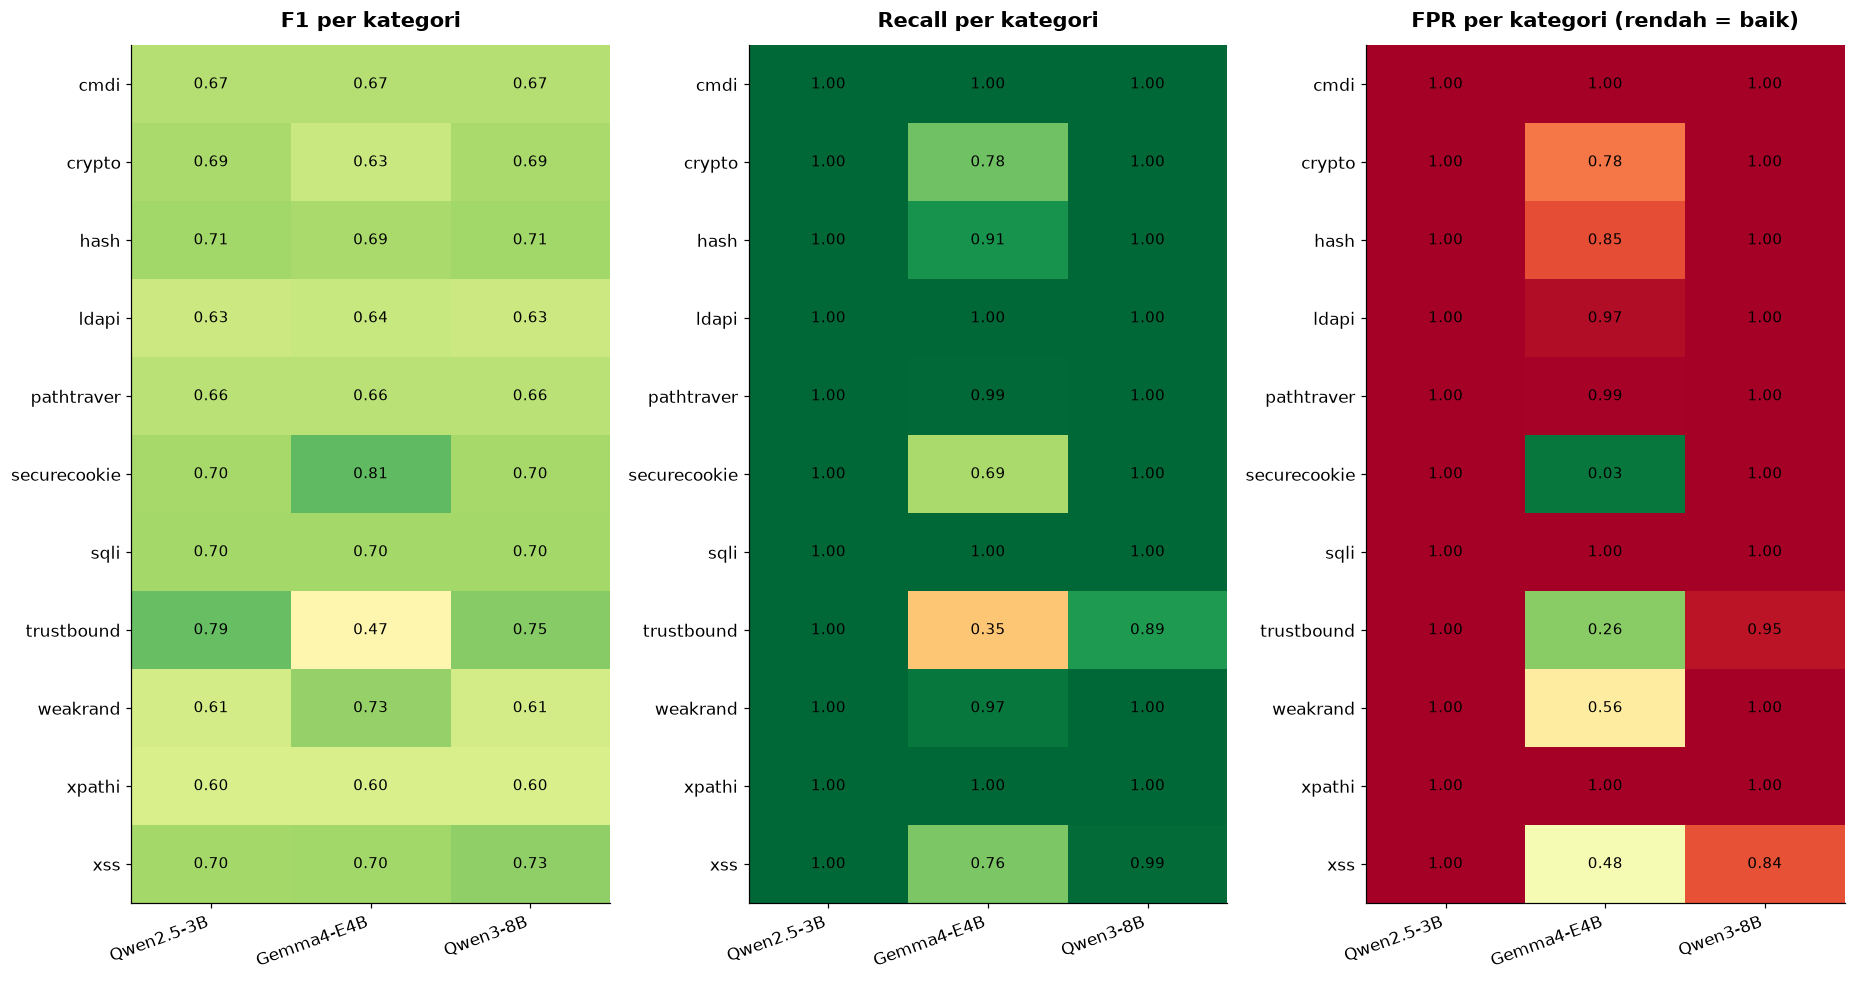

In [60]:
def heatmap(ax, table, title, fmt="{:.2f}", cmap="RdYlGn"):
    values = table.values.astype(float)
    ax.imshow(values, cmap=cmap, vmin=0, vmax=1, aspect="auto")
    ax.grid(False)
    ax.set_xticks(range(table.shape[1]))
    ax.set_xticklabels(table.columns, rotation=20, ha="right")
    ax.set_yticks(range(table.shape[0]))
    ax.set_yticklabels(table.index)
    ax.set_title(title, pad=12)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            v = values[i, j]
            ax.text(j, i, "–" if np.isnan(v) else fmt.format(v), ha="center", va="center", fontsize=10)


cat_counts = (df.groupby(["category", "model", "outcome"]).size()
                .unstack("outcome", fill_value=0)
                .reindex(columns=OUTCOMES, fill_value=0))
cat_det = add_metrics(cat_counts)

f1_cat = cat_det["F1"].unstack("model").reindex(columns=MODELS)
recall_cat = cat_det["Recall"].unstack("model").reindex(columns=MODELS)
fpr_cat = cat_det["FPR"].unstack("model").reindex(columns=MODELS)

fig, axes = plt.subplots(1, 3, figsize=(17, 0.55 * len(f1_cat) + 3))
heatmap(axes[0], f1_cat, "F1 per kategori")
heatmap(axes[1], recall_cat, "Recall per kategori")
heatmap(axes[2], fpr_cat, "FPR per kategori (rendah = baik)", cmap="RdYlGn_r")
plt.tight_layout()
save_fig(fig, "detection_by_category")
plt.show()

save_table(cat_det, "detection_by_category")

## 3. Klasifikasi CWE

Hanya dihitung pada test yang **memang vulnerable** dan punya CWE ground-truth.
Penilaian *exact match*: CWE kosong atau salah dihitung incorrect.

,Comparable,Correct,Incorrect,No_CWE_given,Accuracy
model,,,,,
Qwen2.5-3B,1415,276,1139,0,0.1951
Gemma4-E4B,1415,616,799,171,0.4353
Qwen3-8B,1415,133,1282,11,0.0940


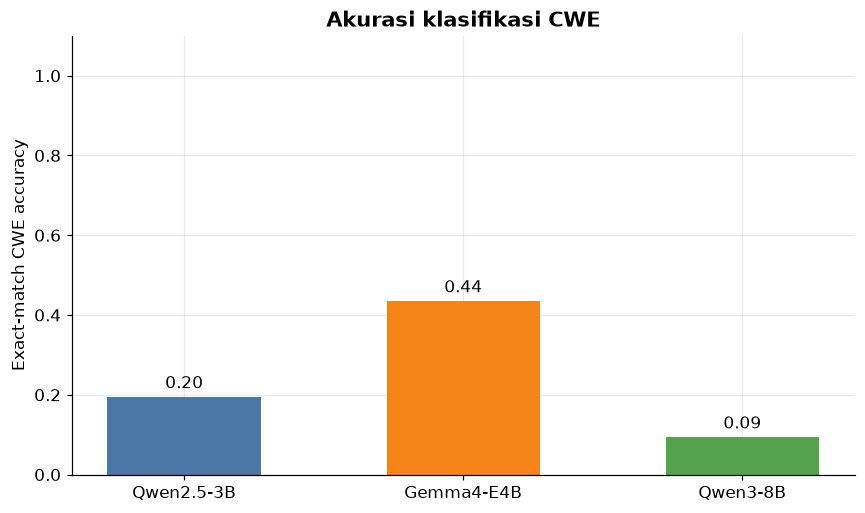

In [61]:
vul = df[df["actual"] & df["cwe_true"].notna()].copy()
vul["cwe_ok"] = vul["cwe_pred"].notna() & (vul["cwe_pred"] == vul["cwe_true"])

cwe_overall = vul.groupby("model").agg(
    Comparable=("cwe_ok", "size"),
    Correct=("cwe_ok", "sum"),
    No_CWE_given=("cwe_pred", lambda s: int(s.isna().sum())),
).reindex(MODELS, fill_value=0)
cwe_overall["Incorrect"] = cwe_overall["Comparable"] - cwe_overall["Correct"]
cwe_overall["Accuracy"] = (cwe_overall["Correct"] / cwe_overall["Comparable"].where(cwe_overall["Comparable"] > 0)).fillna(0.0)
cwe_overall = cwe_overall[["Comparable", "Correct", "Incorrect", "No_CWE_given", "Accuracy"]]

display(cwe_overall.style.format({"Accuracy": "{:.4f}"}).highlight_max(subset=["Accuracy"], color="#0011ac"))
save_table(cwe_overall, "cwe_overall")

fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.bar(MODELS, cwe_overall["Accuracy"], color=[COLORS[m] for m in MODELS], width=0.55)
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Exact-match CWE accuracy")
ax.set_title("Akurasi klasifikasi CWE")
plt.tight_layout()
save_fig(fig, "cwe_accuracy")
plt.show()

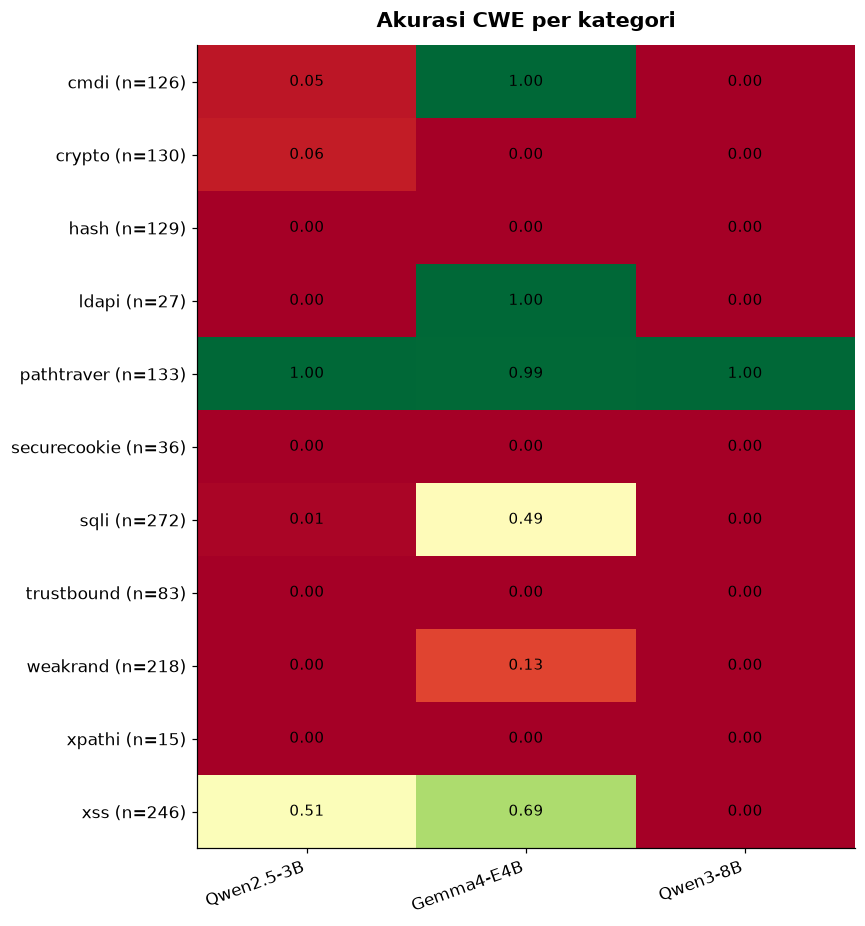

In [62]:
cwe_cat = vul.groupby(["category", "model"])["cwe_ok"].mean().unstack("model").reindex(columns=MODELS)
n_per_cat = gt_df[gt_df["vulnerable"] & gt_df["cwe"].notna()].groupby("category").size()
cwe_cat.index = [f"{c} (n={n_per_cat.get(c, 0)})" for c in cwe_cat.index]

fig, ax = plt.subplots(figsize=(8, 0.55 * len(cwe_cat) + 2.5))
heatmap(ax, cwe_cat, "Akurasi CWE per kategori")
plt.tight_layout()
save_fig(fig, "cwe_by_category")
plt.show()

save_table(cwe_cat, "cwe_by_category")

### Kesalahan CWE yang paling sering

Berguna untuk melihat pola: apakah model salah karena menebak CWE yang berdekatan, atau tidak menyebut CWE sama sekali?

In [63]:
for m in MODELS:
    wrong = vul[(vul["model"] == m) & (~vul["cwe_ok"])]
    display(Markdown(f"**{m}** — {len(wrong):,} prediksi CWE salah"))
    if wrong.empty:
        continue
    top = (wrong.groupby(["cwe_true", wrong["cwe_pred"].fillna("(tidak ada)")])
                .size().sort_values(ascending=False).head(8)
                .rename_axis(["CWE aktual", "CWE prediksi"]).reset_index(name="Jumlah"))
    display(top)

**Qwen2.5-3B** — 1,139 prediksi CWE salah

,CWE aktual,CWE prediksi,Jumlah
0,CWE-89,CWE-22,263
1,CWE-330,CWE-22,132
2,CWE-327,CWE-22,122
3,CWE-78,CWE-22,115
4,CWE-328,CWE-22,103
5,CWE-79,CWE-22,77
6,CWE-330,CWE-20,70
7,CWE-501,CWE-22,63


**Gemma4-E4B** — 799 prediksi CWE salah

,CWE aktual,CWE prediksi,Jumlah
0,CWE-330,CWE-311,126
1,CWE-89,CWE-22,85
2,CWE-328,CWE-200,84
3,CWE-327,CWE-200,77
4,CWE-79,(tidak ada),58
5,CWE-501,(tidak ada),54
6,CWE-327,(tidak ada),28
7,CWE-330,CWE-312,24


**Qwen3-8B** — 1,282 prediksi CWE salah

,CWE aktual,CWE prediksi,Jumlah
0,CWE-89,CWE-22,272
1,CWE-79,CWE-22,244
2,CWE-330,CWE-22,212
3,CWE-327,CWE-22,130
4,CWE-328,CWE-22,129
5,CWE-78,CWE-22,126
6,CWE-501,CWE-22,74
7,CWE-614,CWE-22,36


## 4. Waktu analisis

Dihitung dari penjumlahan `elapsed_seconds` pada record yang berhasil.
Kolom **Est. hours (full dataset)** mengekstrapolasi rata-rata per test ke seluruh dataset, supaya adil jika jumlah test yang tercatat berbeda antar model.

,Tests timed,Total minutes,Total hours,Avg sec/test,Median sec/test,Est. hours (full dataset)
Qwen2.5-3B,"2,740",198.8,3.31,4.35,4.18,3.31
Gemma4-E4B,"2,740",666.3,11.10,14.59,13.93,11.10
Qwen3-8B,"2,740",791.1,13.18,17.32,16.66,13.18


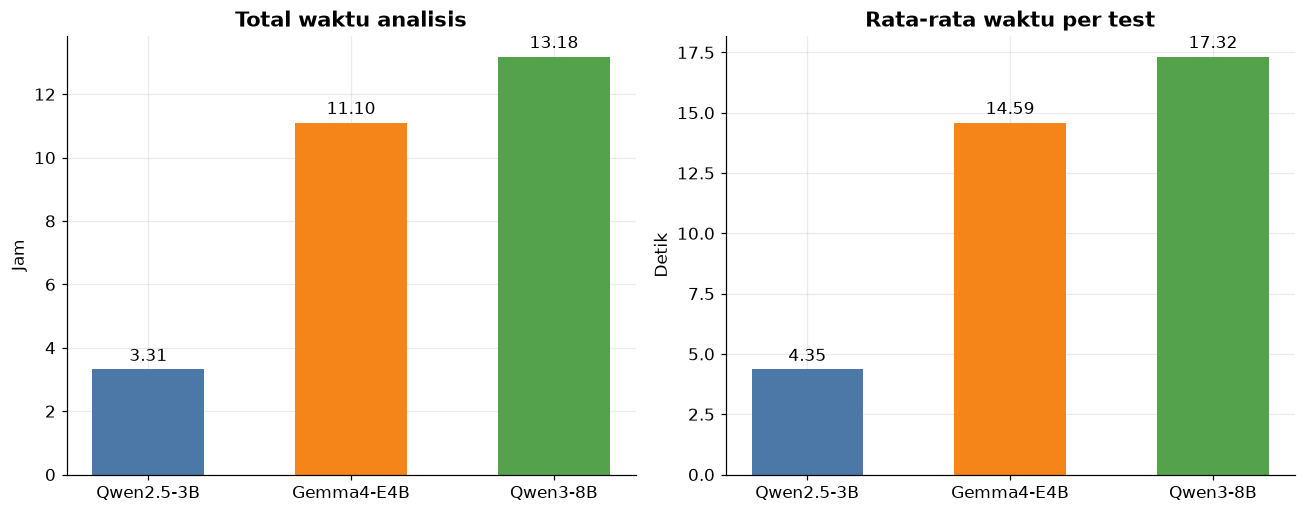

In [64]:
time_df = pd.DataFrame({
    m: {
        "Tests timed": len(t),
        "Total minutes": sum(t) / 60,
        "Total hours": sum(t) / 3600,
        "Avg sec/test": (sum(t) / len(t)) if t else 0.0,
        "Median sec/test": float(np.median(t)) if t else 0.0,
        "Est. hours (full dataset)": ((sum(t) / len(t)) * N / 3600) if t else 0.0,
    }
    for m, (_, t, _) in data.items()
}).T
display(time_df.style.format({
    "Tests timed": "{:,.0f}", "Total minutes": "{:,.1f}", "Total hours": "{:,.2f}",
    "Avg sec/test": "{:.2f}", "Median sec/test": "{:.2f}", "Est. hours (full dataset)": "{:,.2f}",
}).highlight_min(subset=["Avg sec/test"], color="#0011ac"))
save_table(time_df, "time")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, col, title, label in [
    (axes[0], "Total hours", "Total waktu analisis", "Jam"),
    (axes[1], "Avg sec/test", "Rata-rata waktu per test", "Detik"),
]:
    bars = ax.bar(MODELS, time_df[col], color=[COLORS[m] for m in MODELS], width=0.55)
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set_ylabel(label)
    ax.set_title(title)
plt.tight_layout()
save_fig(fig, "time")
plt.show()

## 5. Kesimpulan otomatis

Ringkasan di bawah dihasilkan dari angka di atas, jadi selalu sinkron dengan data terbaru.

In [65]:
def best(series, highest=True):
    idx = series.idxmax() if highest else series.idxmin()
    return idx, series[idx]


lines = []
for label, series, hi, f in [
    ("F1 deteksi tertinggi", det["F1"], True, "{:.3f}"),
    ("Recall tertinggi (paling sedikit kerentanan terlewat)", det["Recall"], True, "{:.3f}"),
    ("Precision tertinggi (paling sedikit alarm palsu)", det["Precision"], True, "{:.3f}"),
    ("FPR terendah", det["FPR"], False, "{:.3f}"),
    ("Akurasi CWE tertinggi", cwe_overall["Accuracy"], True, "{:.3f}"),
    ("Paling cepat (rata-rata detik/test)", time_df["Avg sec/test"], False, "{:.2f}"),
]:
    name, val = best(series, hi)
    lines.append(f"- **{label}:** {name} ({f.format(val)})")

mean_f1 = f1_cat.mean(axis=1).dropna()
if not mean_f1.empty:
    lines.append(f"- **Kategori paling sulit (rata-rata F1 terendah):** {mean_f1.idxmin()} ({mean_f1.min():.3f})")
    lines.append(f"- **Kategori paling mudah (rata-rata F1 tertinggi):** {mean_f1.idxmax()} ({mean_f1.max():.3f})")

low_cov = coverage[coverage["Coverage (%)"] < 95]
if not low_cov.empty:
    lines.append("- **Perhatian:** cakupan prediksi valid < 95% pada " + ", ".join(low_cov.index)
                 + " — metrik model tersebut dihitung dari subset test.")

display(Markdown("\n".join(lines)))

- **F1 deteksi tertinggi:** Qwen3-8B (0.683)
- **Recall tertinggi (paling sedikit kerentanan terlewat):** Qwen2.5-3B (1.000)
- **Precision tertinggi (paling sedikit alarm palsu):** Gemma4-E4B (0.557)
- **FPR terendah:** Gemma4-E4B (0.746)
- **Akurasi CWE tertinggi:** Gemma4-E4B (0.435)
- **Paling cepat (rata-rata detik/test):** Qwen2.5-3B (4.35)
- **Kategori paling sulit (rata-rata F1 terendah):** xpathi (0.600)
- **Kategori paling mudah (rata-rata F1 tertinggi):** securecookie (0.735)

## 6. Ekspor

Semua tabel tersimpan sebagai CSV di `results/comparison/tables/` dan semua grafik sebagai PNG (200 dpi) di `results/comparison/figures/`.

In [66]:
print("Grafik:")
for p in sorted(FIG_DIR.glob("*.png")):
    print("  ", p.relative_to(ROOT))
print("Tabel:")
for p in sorted(TABLE_DIR.glob("*.csv")):
    print("  ", p.relative_to(ROOT))

Grafik:
   results/comparison/figures/cwe_accuracy.png
   results/comparison/figures/cwe_by_category.png
   results/comparison/figures/detection_by_category.png
   results/comparison/figures/detection_confusion_matrix.png
   results/comparison/figures/detection_metrics.png
   results/comparison/figures/time.png
   results/comparison/figures/tradeoff_f1_vs_time.png
Tabel:
   results/comparison/tables/coverage.csv
   results/comparison/tables/cwe_by_category.csv
   results/comparison/tables/cwe_overall.csv
   results/comparison/tables/dataset_overview.csv
   results/comparison/tables/detection_by_category.csv
   results/comparison/tables/detection_overall.csv
   results/comparison/tables/time.csv


## Definisi evaluasi

- **Detection:** seluruh test dengan prediksi valid; positive class = vulnerable. Prediksi yang hilang/gagal di-parse **tidak** dihitung (lihat tabel cakupan).
- **Precision** = TP / (TP + FP) &nbsp;·&nbsp; **Recall** = TP / (TP + FN) &nbsp;·&nbsp; **F1** = rata-rata harmonik Precision dan Recall
- **Accuracy** = (TP + TN) / total &nbsp;·&nbsp; **FPR** = FP / (FP + TN)
- **CWE classification:** hanya test vulnerable dengan ground-truth CWE valid; *exact match*; CWE kosong dihitung incorrect.
- **Waktu:** total `elapsed_seconds` dari record berhasil di raw JSONL tiap model.
- **Ground truth:** `benchmark/BenchmarkJava/expectedresults-1.2.csv`.